In [1]:
# ----------------------------------------
# LOAD DATA
# ----------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import r2_score, mean_squared_error

file_path = "Nutrition data.xlsx"
df = pd.read_excel(file_path)

# Selected variables
vars_list = [
    "BMI_DECIMAL","BMI_Deci_class","V106","NV717","V190","NV012","NV212","NV511","NV201",
    "V404","NV312","V406","V405","NV418","NV419","NV467B","NV467D","NV730","V701",
    "NV705","NV467C","Media_access","NV113","NV130","NV136","V025","Family_planning"
]

df = df[vars_list]
df.head()


,BMI_DECIMAL,BMI_Deci_class,V106,NV717,V190,NV012,NV212,NV511,NV201,V404,...,NV730,V701,NV705,NV467C,Media_access,NV113,NV130,NV136,V025,Family_planning
0,99.98,4,0,1,1,3,1,1,1,0,...,3,1,1,1,0,1,1,1,2,0
1,56.71,4,0,1,3,2,1,1,1,0,...,1,1,1,0,1,1,1,1,2,1
2,38.96,4,0,0,4,3,1,1,1,0,...,3,2,1,0,1,1,1,1,2,1
3,38.29,4,0,0,5,2,1,1,1,0,...,2,2,1,1,1,1,1,1,1,1
4,37.73,4,0,0,5,3,1,1,1,0,...,2,0,1,1,1,1,1,1,1,1


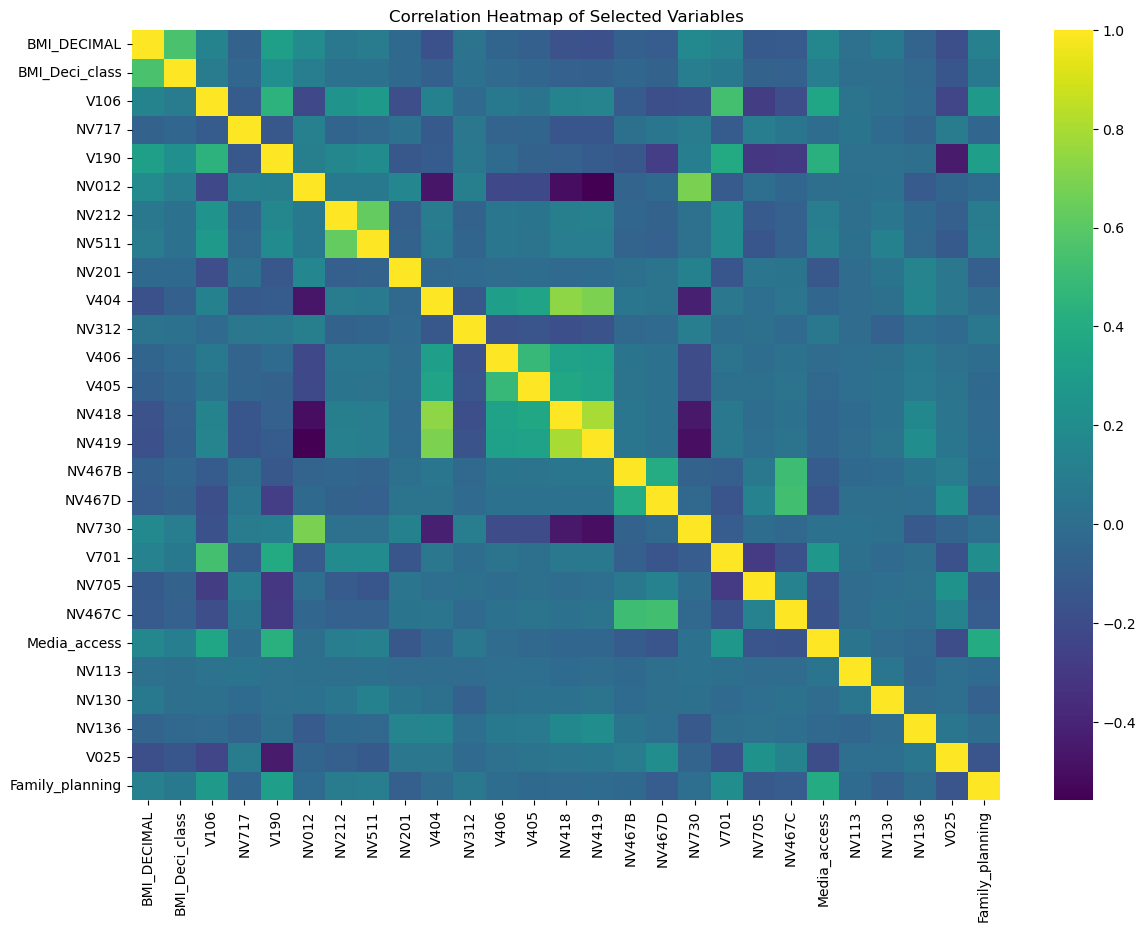

In [2]:
# ----------------------------------------
# CORRELATION HEATMAP
# ----------------------------------------
plt.figure(figsize=(14, 10))
corr = df.corr()
sns.heatmap(corr, annot=False, cmap="viridis")
plt.title("Correlation Heatmap of Selected Variables")
plt.show()


In [3]:
# ----------------------------------------
# CLEANING
# ----------------------------------------

# Remove unrealistic BMI values
df = df[df["BMI_DECIMAL"] > 0]

# Fill missing values with median
df = df.fillna(df.median(numeric_only=True))

df_cleaned = df.copy()
df_cleaned.head()


,BMI_DECIMAL,BMI_Deci_class,V106,NV717,V190,NV012,NV212,NV511,NV201,V404,...,NV730,V701,NV705,NV467C,Media_access,NV113,NV130,NV136,V025,Family_planning
0,99.98,4,0,1,1,3,1,1,1,0,...,3,1,1,1,0,1,1,1,2,0
1,56.71,4,0,1,3,2,1,1,1,0,...,1,1,1,0,1,1,1,1,2,1
2,38.96,4,0,0,4,3,1,1,1,0,...,3,2,1,0,1,1,1,1,2,1
3,38.29,4,0,0,5,2,1,1,1,0,...,2,2,1,1,1,1,1,1,1,1
4,37.73,4,0,0,5,3,1,1,1,0,...,2,0,1,1,1,1,1,1,1,1


In [4]:
# ----------------------------------------
# MULTIPLE LINEAR REGRESSION
# ----------------------------------------

X = df_cleaned.drop(["BMI_DECIMAL", "BMI_Deci_class"], axis=1)
y = df_cleaned["BMI_DECIMAL"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42)

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

y_pred = model_lr.predict(X_test)

print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# Coefficients
coef_df = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model_lr.coef_
})
coef_df


R² Score: 0.14460686471199435
RMSE: 5.45785232348725


,Variable,Coefficient
0,V106,0.180718
1,NV717,-0.295311
2,V190,1.236869
3,NV012,0.427108
4,NV212,-0.041354
5,NV511,0.075824
6,NV201,0.013821
7,V404,-0.266604
8,NV312,-0.056469
9,V406,0.120208


In [5]:
# ----------------------------------------
# MULTINOMIAL LOGISTIC REGRESSION
# ----------------------------------------

X = df_cleaned.drop(["BMI_DECIMAL", "BMI_Deci_class"], axis=1)
y = df_cleaned["BMI_Deci_class"]

X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42
)

log_reg = LogisticRegression(max_iter=1000, multi_class="multinomial")
log_reg.fit(X_train, y_train)
y_pred = log_reg.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


C:\Users\Ketan Gaikwad\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.436115092051593

Classification Report:
               precision    recall  f1-score   support

           1       0.37      0.13      0.19      2624
           2       0.50      0.58      0.53      2117
           3       0.42      0.74      0.54      3271
           4       0.00      0.00      0.00      1059

    accuracy                           0.44      9071
   macro avg       0.32      0.36      0.31      9071
weighted avg       0.37      0.44      0.37      9071



C:\Users\Ketan Gaikwad\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Ketan Gaikwad\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Ketan Gaikwad\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


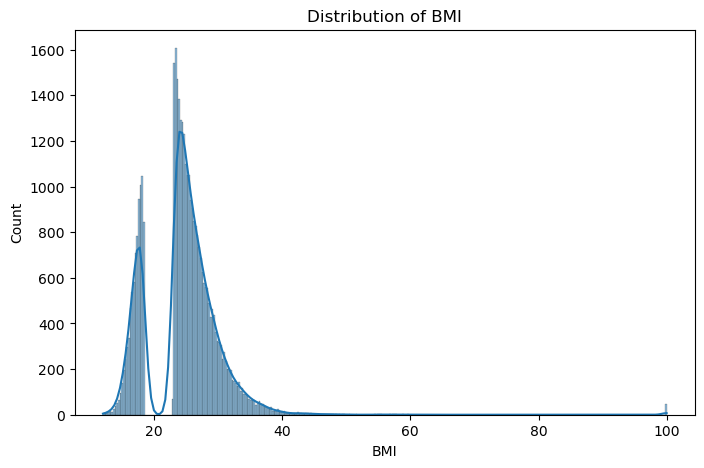

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(df_cleaned["BMI_DECIMAL"], kde=True)
plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.show()


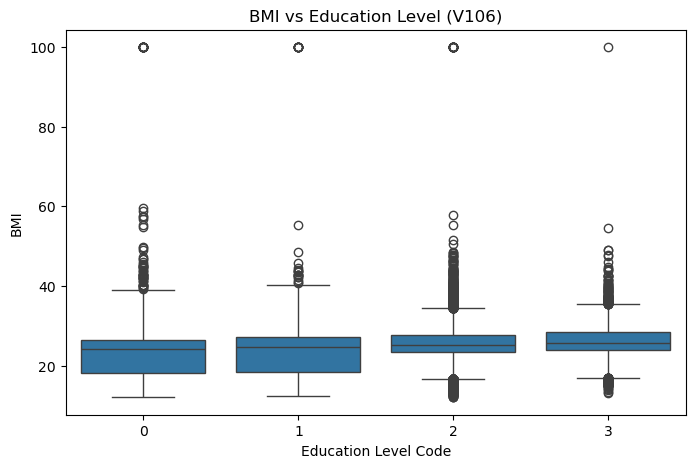

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df_cleaned["V106"], y=df_cleaned["BMI_DECIMAL"])
plt.title("BMI vs Education Level (V106)")
plt.xlabel("Education Level Code")
plt.ylabel("BMI")
plt.show()
